# 2 — Data cleaning (complete-case cohorts)

We apply the same rules on development and external data:

1. **Invalid NHANES codes** (7, 9, 77, 99, etc.) → treated as missing; rows with invalid categorical answers on OSQ/DIQ/Gender are dropped.
2. **T-score** from femoral-neck BMD (based on the original article's. Peak bone density reference coordinates for femoral necks were mapped against parameters derived from non-Hispanic white female cohorts in NHANES III): `(DXXNKBMD − 0.858) / 0.120`.
3. **TARGET = 1 (low BMD)** if T-score ≤ −0.99 **or** self-reported osteoporosis/fracture (`OSQ060 == 1`).
4. **Complete cases only** — any row with a missing predictor is excluded (no imputation).

**Note:** `OSQ060` is used to define TARGET but is **excluded from model predictors** (see article for explanation).

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from experiment_utils import (
    RAW_DEV_PATH,
    EXTERNAL_PATH,
    DEV_CLEAN_PATH,
    EXTERNAL_CLEAN_PATH,
    MODEL_FEATURES,
    LABEL_COL,
    prepare_development_raw,
    prepare_external,
    ensure_dirs,
)

ensure_dirs()

## 2.1 Clean development cohort

In [7]:
df_raw = pd.read_csv(RAW_DEV_PATH)
df_dev = prepare_development_raw(df_raw)

print(f'Raw development rows: {len(df_raw)}')
print(f'Complete-case development rows: {len(df_dev)}')
print(f'Excluded: {len(df_raw) - len(df_dev)} ({100 * (len(df_raw) - len(df_dev)) / len(df_raw):.1f}%)')
print(f'\nTARGET prevalence: {df_dev[LABEL_COL].mean():.3f}')
print(df_dev[LABEL_COL].value_counts())

Raw development rows: 3545
Complete-case development rows: 2591
Excluded: 954 (26.9%)

TARGET prevalence: 0.474
TARGET
0    1362
1    1229
Name: count, dtype: int64


## 2.2 Clean external cohort (complete cases, no imputation)

In [8]:
df_ext_raw = pd.read_csv(EXTERNAL_PATH)
df_external = prepare_external(df_ext_raw)

print(f'External rows (saved file): {len(df_ext_raw)}')
print(f'Complete-case external rows: {len(df_external)}')
print(f'TARGET prevalence: {df_external[LABEL_COL].mean():.3f}')

External rows (saved file): 1728
Complete-case external rows: 1728
TARGET prevalence: 0.492


## 2.3 Compare TARGET and gender distributions

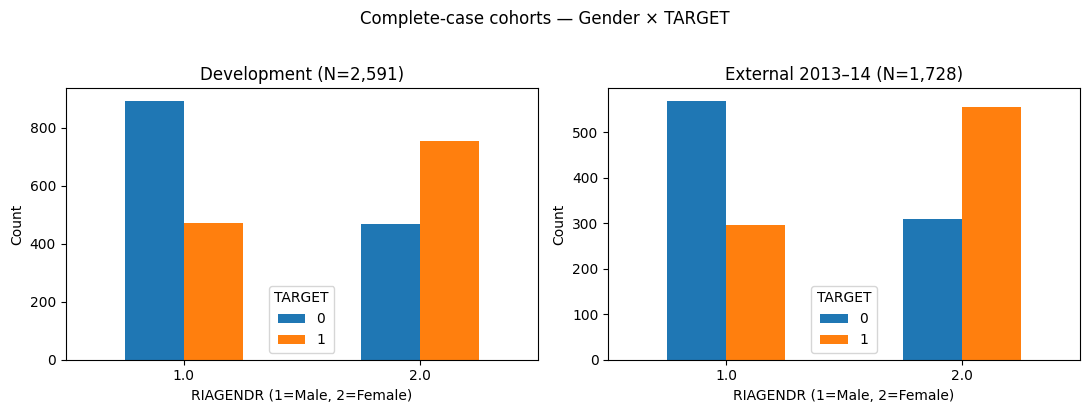

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, df) in zip(
    axes,
    [('Development', df_dev), ('External 2013–14', df_external)],
):
    counts = df.groupby(['RIAGENDR', LABEL_COL]).size().unstack(fill_value=0)
    counts.plot(kind='bar', ax=ax, rot=0)
    ax.set_title(f'{name} (N={len(df):,})')
    ax.set_xlabel('RIAGENDR (1=Male, 2=Female)')
    ax.set_ylabel('Count')

plt.suptitle('Complete-case cohorts — Gender × TARGET', y=1.02)
plt.tight_layout()
plt.show()

## 2.4 Save cleaned tables

In [10]:
df_dev.to_csv(DEV_CLEAN_PATH, index=False)
df_external.to_csv(EXTERNAL_CLEAN_PATH, index=False)
print(f'Saved: {DEV_CLEAN_PATH}')
print(f'Saved: {EXTERNAL_CLEAN_PATH}')

Saved: /Users/vassilis/Documents/OP_article/DATA/DEV_CLEAN_COMPLETE.csv
Saved: /Users/vassilis/Documents/OP_article/DATA/EXTERNAL_CLEAN_COMPLETE.csv


**Next:** `3_DATA_SPLITTING.ipynb` creates the stratified 70/30 development split.